# 02: The neural net learns to hedge

Small MLP, fresh paths every batch (infinite data, no overfitting), CVaR as the loss. Let's see if it actually beats Black-Scholes or just memorizes noise.

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt
from dhl.markets import simulate_gbm
from dhl.derivatives import european_call, bs_call_price
from dhl.hedgers import DeepHedger, train_deep_hedger, hedging_error, bs_delta_hedge
from dhl.risk import cvar

S0, K, T, r, sigma = 100.0, 100.0, 0.25, 0.02, 0.25
n_steps, dt, cost = 30, T / 30, 0.002
p0 = bs_call_price(S0, K, T, r, sigma)

epoch   20/120  objective=9.122082  p0=5.2438


epoch   40/120  objective=8.896708  p0=5.2619


epoch   60/120  objective=8.408297  p0=5.2781


epoch   80/120  objective=6.820559  p0=5.2906


epoch  100/120  objective=5.247960  p0=5.2999


epoch  120/120  objective=4.426634  p0=5.3092


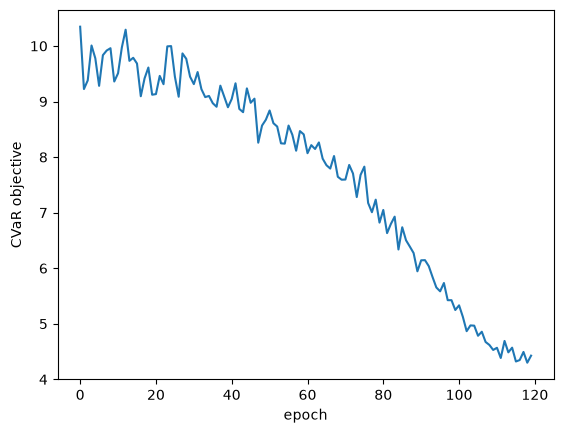

In [2]:
model = DeepHedger(hidden_dims=(32, 32), architecture="mlp", p0_init=p0)
history = train_deep_hedger(
    model,
    sample_paths=lambda n, seed: simulate_gbm(n, n_steps, T, S0, r, sigma, seed=seed),
    payoff_fn=lambda S: european_call(S, K),
    K=K, r=r, dt=dt, cost_rate=cost,
    risk_fn=lambda L: cvar(L, 0.95),
    n_epochs=120, batch_size=2048, lr=1e-3, seed=0, log_every=20,
)
plt.plot(history); plt.xlabel("epoch"); plt.ylabel("CVaR objective");

/tmp/ipykernel_4663/3543004794.py:6: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  e_deep = hedging_error(St, torch.as_tensor(d_deep), pt, float(model.p0), r, dt, cost).numpy()


deep hedge std=1.8907  CVaR95=+4.2310  learned p0=5.3092
bs delta   std=0.8221  CVaR95=+2.5146  learned p0=5.3092


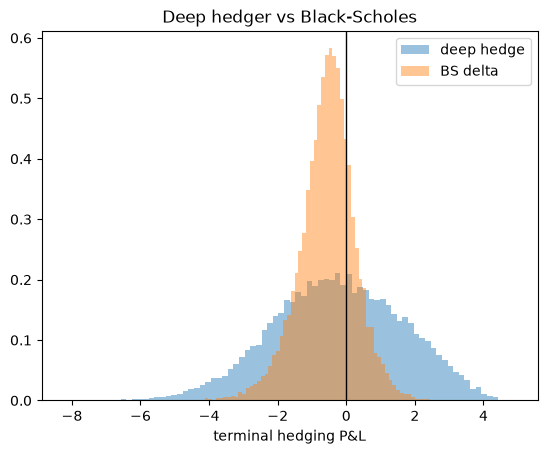

In [3]:
S = simulate_gbm(20000, n_steps, T, S0, r, sigma, seed=123)
payoff = european_call(S, K)
St, pt = torch.as_tensor(S, dtype=torch.float32), torch.as_tensor(payoff, dtype=torch.float32)
with torch.no_grad():
    d_deep = model(St, K, dt).numpy()
e_deep = hedging_error(St, torch.as_tensor(d_deep), pt, float(model.p0), r, dt, cost).numpy()
e_bs = hedging_error(St, torch.as_tensor(bs_delta_hedge(S, K, r, sigma, dt)), pt, p0, r, dt, cost).numpy()

for name, e in [("deep hedge", e_deep), ("bs delta", e_bs)]:
    tail = np.sort(e)[-int(0.05 * len(e)):].mean()
    print(f"{name:10s} std={e.std():.4f}  CVaR95={tail:+.4f}  learned p0={float(model.p0):.4f}")

plt.hist(-e_deep, bins=80, alpha=0.45, label="deep hedge", density=True)
plt.hist(-e_bs, bins=80, alpha=0.45, label="BS delta", density=True)
plt.axvline(0, color="k", lw=1); plt.legend()
plt.xlabel("terminal hedging P&L"); plt.title("Deep hedger vs Black-Scholes");

**What happened:** it worked. The P&L distribution tightens and the left tail shrinks. My read on *why*: it's learned a no-trade region around the BS delta, i.e. it rediscovered Leland's intuition without being told. Notebook 03 is the real test: stochastic vol, where the formula hedge is wrong.